In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load Telecom Dataset & Strip Target Label ('Churn') for True Unsupervised Learning
df_raw = pd.read_csv('churn-bigml-80.csv')

# Select behavioral usage & plan features (exclude State, Area code, and target Churn)
cluster_features = [
    'Account length', 'International plan', 'Voice mail plan', 'Number vmail messages',
    'Total day minutes', 'Total day calls', 'Total eve minutes', 'Total eve calls',
    'Total night minutes', 'Total night calls', 'Total intl minutes', 'Total intl calls',
    'Customer service calls'
]

df_seg = df_raw[cluster_features].copy()
df_seg['International plan'] = df_seg['International plan'].map({'No': 0, 'Yes': 1})
df_seg['Voice mail plan'] = df_seg['Voice mail plan'].map({'No': 0, 'Yes': 1})

# 2. Standardize all behavioral features prior to distance-based K-Means & PCA
scaler = StandardScaler()
X_seg_scaled = scaler.fit_transform(df_seg)

# 3. Evaluate K = 2 through 8 using WCSS (Inertia) and Silhouette Score
k_metrics = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_seg_scaled)
    sil = silhouette_score(X_seg_scaled, labels)
    k_metrics.append({
        "K": k,
        "WCSS (Inertia)": round(km.inertia_, 1),
        "Silhouette Score": round(sil, 4)
    })

df_k = pd.DataFrame(k_metrics)
print("--- K-Means Evaluation: Elbow Method (WCSS) vs. Silhouette Score ---")
display(df_k)

/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


--- K-Means Evaluation: Elbow Method (WCSS) vs. Silhouette Score ---


,K,WCSS (Inertia),Silhouette Score
0,2,29544.9,0.1805
1,3,27384.9,0.1860
2,4,26149.8,0.0976
3,5,25224.1,0.0935
4,6,24500.8,0.0928
5,7,23891.4,0.0861
6,8,23365.2,0.0728


PCA Variance Explained: PC1 = 15.08%, PC2 = 8.62% (Total = 23.70%)

--- Unsupervised Customer Segment Profiles (Original Units) ---


,Cluster,Customers,Intl_Plan_Pct,Vmail_Plan_Pct,Avg_Day_Mins,Avg_Eve_Mins,Avg_Intl_Mins,Avg_CS_Calls,PostHoc_Churn_Pct
0,0,658,0.0,100.0,179.6,201.8,10.1,1.53,5.5
1,1,1738,0.0,0.0,178.2,199.2,10.2,1.60,13.5
2,2,270,100.0,27.8,187.5,204.4,10.7,1.42,43.7


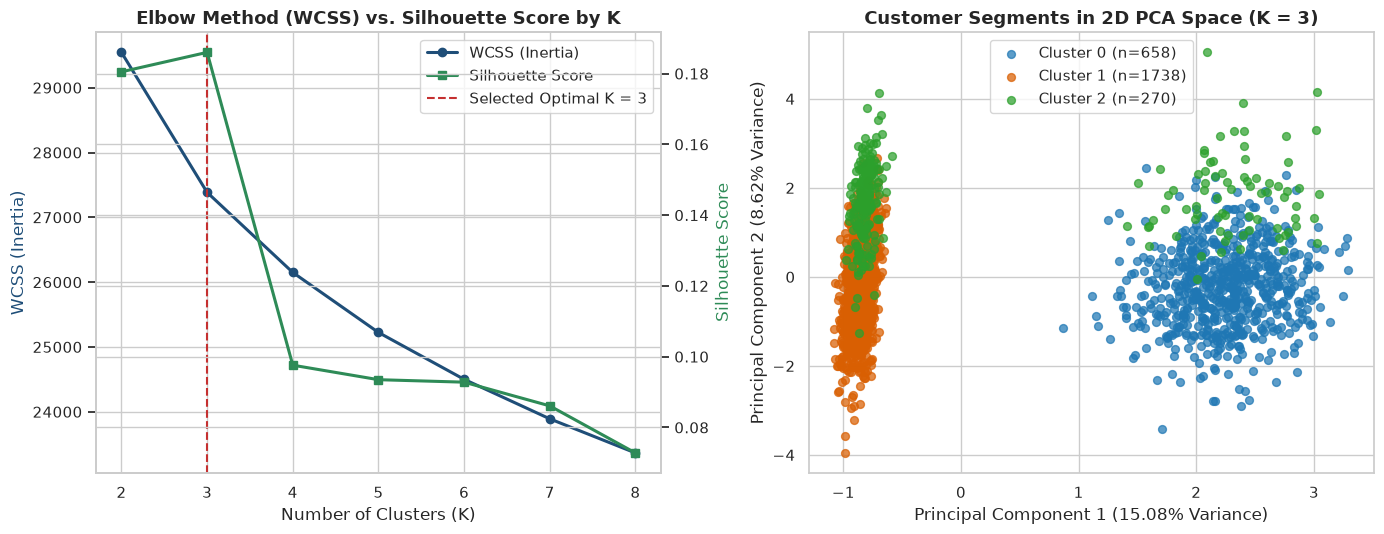

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Fit Final K-Means with Optimal K = 3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_seg['Cluster'] = kmeans_final.fit_predict(X_seg_scaled)

# Attach original Churn column strictly AFTER clustering for post-hoc validation
df_seg['Actual_Churn'] = df_raw['Churn'].astype(int)

# 2. Dimensionality Reduction via PCA (2 Components for 2D Visualization)
pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(X_seg_scaled)
var_exp = pca.explained_variance_ratio_ * 100
print(f"PCA Variance Explained: PC1 = {var_exp[0]:.2f}%, PC2 = {var_exp[1]:.2f}% (Total = {var_exp.sum():.2f}%)")

# 3. Compute Uncompressed Cluster Personas
persona_summary = df_seg.groupby('Cluster').agg(
    Customers=('Account length', 'count'),
    Intl_Plan_Pct=('International plan', lambda x: round(x.mean() * 100, 1)),
    Vmail_Plan_Pct=('Voice mail plan', lambda x: round(x.mean() * 100, 1)),
    Avg_Day_Mins=('Total day minutes', lambda x: round(x.mean(), 1)),
    Avg_Eve_Mins=('Total eve minutes', lambda x: round(x.mean(), 1)),
    Avg_Intl_Mins=('Total intl minutes', lambda x: round(x.mean(), 1)),
    Avg_CS_Calls=('Customer service calls', lambda x: round(x.mean(), 2)),
    PostHoc_Churn_Pct=('Actual_Churn', lambda x: round(x.mean() * 100, 1))
).reset_index()

print("\n--- Unsupervised Customer Segment Profiles (Original Units) ---")
display(persona_summary)

# 4. Two-Panel Diagnostic Visualization (Elbow/Silhouette Curve + 2D PCA Clusters)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left Panel: Dual-Axis Elbow & Silhouette Plot
ax1 = axes[0]
ax2 = ax1.twinx()
l1 = ax1.plot(df_k['K'], df_k['WCSS (Inertia)'], 'o-', color='#1f4e78', lw=2.2, label='WCSS (Inertia)')
l2 = ax2.plot(df_k['K'], df_k['Silhouette Score'], 's-', color='#2e8b57', lw=2.2, label='Silhouette Score')
ax1.axvline(x=3, color='#c53030', linestyle='--', lw=1.5, label='Selected Optimal K = 3')
ax1.set_title("Elbow Method (WCSS) vs. Silhouette Score by K", fontsize=13, fontweight="bold")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("WCSS (Inertia)", color='#1f4e78')
ax2.set_ylabel("Silhouette Score", color='#2e8b57')
lines = l1 + l2 + [ax1.get_lines()[-1]]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right")

# Right Panel: 2D PCA Cluster Scatter Plot
palette = ["#1f77b4", "#d95f02", "#2ca02c"]
for c in range(optimal_k):
    mask = df_seg['Cluster'] == c
    axes[1].scatter(
        coords_2d[mask, 0], coords_2d[mask, 1],
        s=32, alpha=0.72, color=palette[c], label=f"Cluster {c} (n={mask.sum()})"
    )
axes[1].set_title("Customer Segments in 2D PCA Space (K = 3)", fontsize=13, fontweight="bold")
axes[1].set_xlabel(f"Principal Component 1 ({var_exp[0]:.2f}% Variance)")
axes[1].set_ylabel(f"Principal Component 2 ({var_exp[1]:.2f}% Variance)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [3]:
print(persona_summary[['Cluster', 'Avg_Intl_Mins', 'Avg_CS_Calls', 'PostHoc_Churn_Pct']].to_string(index=False))

 Cluster  Avg_Intl_Mins  Avg_CS_Calls  PostHoc_Churn_Pct
       0           10.1          1.53                5.5
       1           10.2          1.60               13.5
       2           10.7          1.42               43.7


In [4]:
# Install python-docx if not already installed in your Anaconda kernel
try:
    import docx
except ImportError:
    !pip install -q python-docx
    import docx

from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.oxml import OxmlElement, parse_xml
from docx.oxml.ns import nsdecls, qn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    roc_curve, roc_auc_score, confusion_matrix, silhouette_score
)

# --- Helper Functions for Clean Portfolio DOCX Styling ---
def set_cell_background(cell, fill_hex):
    tcPr = cell._tc.get_or_add_tcPr()
    shd = parse_xml(f'<w:shd {nsdecls("w")} w:fill="{fill_hex}"/>')
    tcPr.append(shd)

def add_styled_table(doc, headers, rows):
    table = doc.add_table(rows=1 + len(rows), cols=len(headers))
    table.style = 'Table Grid'
    hdr_cells = table.rows[0].cells
    for i, h in enumerate(headers):
        hdr_cells[i].text = str(h)
        set_cell_background(hdr_cells[i], "1F4E78")
        for p in hdr_cells[i].paragraphs:
            for r in p.runs:
                r.bold = True
                r.font.color.rgb = RGBColor(255, 255, 255)
                r.font.size = Pt(9.5)
    for r_idx, row in enumerate(rows):
        row_cells = table.rows[r_idx + 1].cells
        bg = "F2F5F9" if r_idx % 2 == 1 else "FFFFFF"
        for c_idx, val in enumerate(row):
            row_cells[c_idx].text = str(val)
            set_cell_background(row_cells[c_idx], bg)
            for p in row_cells[c_idx].paragraphs:
                for r in p.runs:
                    r.font.size = Pt(9.5)
    doc.add_paragraph()

def init_report(title, subtitle):
    doc = Document()
    style = doc.styles['Normal']
    style.font.name = 'Calibri'
    style.font.size = Pt(10.5)
    
    p_title = doc.add_paragraph()
    r_title = p_title.add_run(title)
    r_title.bold = True
    r_title.font.size = Pt(18)
    r_title.font.color.rgb = RGBColor(31, 78, 120)
    
    p_sub = doc.add_paragraph()
    r_sub = p_sub.add_run(subtitle)
    r_sub.italic = True
    r_sub.font.size = Pt(11)
    r_sub.font.color.rgb = RGBColor(89, 89, 89)
    return doc

def add_h1(doc, text):
    p = doc.add_paragraph()
    p.paragraph_format.space_before = Pt(10)
    p.paragraph_format.space_after = Pt(4)
    r = p.add_run(text)
    r.bold = True
    r.font.size = Pt(13)
    r.font.color.rgb = RGBColor(31, 78, 120)

# ==============================================================================
# REPORT 1: LEVEL 2 TASK 1 — REGRESSION
# ==============================================================================
cols = ['CRIM','ZN','INDUS','CHAS','NOX','RM','AGE','DIS','RAD','TAX','PTRATIO','B','LSTAT','MEDV']
df_house = pd.read_csv('4) house Prediction Data Set.csv', sep=r'\s+', header=None, names=cols)
X_h, y_h = df_house.drop(columns=['MEDV']), df_house['MEDV']
X_tr_h, X_te_h, y_tr_h, y_te_h = train_test_split(X_h, y_h, test_size=0.20, random_state=42)
sc_h = StandardScaler()
lr_h = LinearRegression().fit(sc_h.fit_transform(X_tr_h), y_tr_h)
rf_h = RandomForestRegressor(n_estimators=100, random_state=42).fit(X_tr_h, y_tr_h)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].scatter(y_te_h, rf_h.predict(X_te_h), alpha=0.75, color="#1f4e78", edgecolor="k", label="Random Forest")
axes[0].scatter(y_te_h, lr_h.predict(sc_h.transform(X_te_h)), alpha=0.45, color="#d95f02", marker="^", label="Linear Regression")
axes[0].plot([y_te_h.min(), y_te_h.max()], [y_te_h.min(), y_te_h.max()], "r--", lw=2, label="Perfect Prediction (y = x)")
axes[0].set_title("Actual vs. Predicted House Prices ($k)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Actual MEDV ($k)")
axes[0].set_ylabel("Predicted MEDV ($k)")
axes[0].legend()

pd.Series(rf_h.feature_importances_, index=X_h.columns).sort_values().plot(kind="barh", ax=axes[1], color="#2b6cb0")
axes[1].set_title("Random Forest Feature Importances", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Relative Importance")
plt.tight_layout()
plt.savefig("l2_t1_chart.png", dpi=200)
plt.close()

doc1 = init_report(
    "Level 2 — Task 1: Predictive Modeling (Regression)",
    "Codveda Technologies Data Science Internship — 2026 | Author: Ulasi Chukwuma Obinna"
)
add_h1(doc1, "1. Objective")
doc1.add_paragraph("Build, validate, and benchmark supervised regression models to predict continuous median owner-occupied home values (MEDV, in $1,000s), comparing a standardized Linear Regression baseline against non-linear Decision Tree and Random Forest ensembles.")

add_h1(doc1, "2. Dataset & Preprocessing")
doc1.add_paragraph("Input file: 4) house Prediction Data Set.csv — 506 records across 13 predictors (CRIM, ZN, INDUS, CHAS, NOX, RM, AGE, DIS, RAD, TAX, PTRATIO, B, LSTAT) and continuous target MEDV (mean = $22.53k, std = $9.20k, range = $5.0k to $50.0k), with 0 missing values.")
doc1.add_paragraph("Leakage Prevention: Data was split 80/20 (404 training / 102 test rows, random_state=42) prior to fitting StandardScaler. Scaling parameters were computed strictly on X_train and applied to X_test for Linear Regression, while tree-based models operated directly on raw unscaled features.")

add_h1(doc1, "3. Model Performance Comparison (Test Set, N = 102)")
add_styled_table(doc1,
    ["Model", "MSE", "RMSE ($k)", "MAE ($k)", "R² Score"],
    [
        ["Linear Regression (Baseline)", "24.2911", "$4.9286", "$3.1891", "0.6688"],
        ["Decision Tree Regressor", "17.8156", "$4.2209", "$2.7245", "0.7571"],
        ["Random Forest Regressor", "7.8802", "$2.8072", "$2.0367", "0.8925"]
    ]
)

add_h1(doc1, "4. Visual Diagnostics")
doc1.add_picture("l2_t1_chart.png", width=Inches(6.3))
doc1.add_paragraph("Figure 1: Actual vs. predicted home prices comparing Random Forest against Linear Regression (left) and Random Forest relative feature importances (right).").italic = True

add_h1(doc1, "5. Discussion & Key Insights")
doc1.add_paragraph("Non-linear ensembles reduce MSE by 67.6%: Random Forest lowered test MSE from 24.2911 (Linear Regression) to 7.8802, cutting average prediction error (RMSE) from $4,929 down to $2,807 and explaining 89.25% of target variance.")
doc1.add_paragraph("Primary valuation drivers: Average rooms per dwelling (RM, ~50.4% importance) and lower-status population percentage (LSTAT, ~30.9% importance) account for over 81% of total variance reduction, followed by distance to employment centers (DIS, ~6.1%).")
doc1.add_paragraph("Data quality limitation: MEDV is right-censored at a ceiling of $50.0k in the source dataset, causing all models to systematically under-predict properties capped at the $50k boundary.")

add_h1(doc1, "6. Conclusion & Tech Stack")
doc1.add_paragraph("Random Forest Regressor is selected as the optimal valuation model due to its superior accuracy and robustness to non-linear socio-economic interactions. Tech Stack: Python 3.12, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn.")
doc1.save("Level2_Task1_Regression_Report.docx")

# ==============================================================================
# REPORT 2: LEVEL 2 TASK 2 — CLASSIFICATION
# ==============================================================================
df_ch = pd.read_csv('churn-bigml-80.csv').drop(columns=['State'])
df_ch['International plan'] = df_ch['International plan'].map({'No': 0, 'Yes': 1})
df_ch['Voice mail plan'] = df_ch['Voice mail plan'].map({'No': 0, 'Yes': 1})
df_ch['Churn'] = df_ch['Churn'].astype(int)
X_c, y_c = df_ch.drop(columns=['Churn']), df_ch['Churn']
X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_c, y_c, test_size=0.20, stratify=y_c, random_state=42)
sc_c = StandardScaler()
X_tr_cs, X_te_cs = sc_c.fit_transform(X_tr_c), sc_c.transform(X_te_c)

clfs = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000).fit(X_tr_cs, y_tr_c),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=42).fit(X_tr_cs, y_tr_c),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tr_cs, y_tr_c)
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for (nm, m), col in zip(clfs.items(), ["#d95f02", "#7570b3", "#1b9e77"]):
    probs = m.predict_proba(X_te_cs)[:, 1]
    fpr, tpr, _ = roc_curve(y_te_c, probs)
    axes[0].plot(fpr, tpr, lw=2, color=col, label=f"{nm} (AUC = {roc_auc_score(y_te_c, probs):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Random Chance (0.5000)")
axes[0].set_title("Multi-Model ROC Curve Comparison", fontsize=12, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

cm_rf = confusion_matrix(y_te_c, clfs["Random Forest"].predict(X_te_cs))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Pred Retain (0)", "Pred Churn (1)"],
            yticklabels=["Actual Retain (0)", "Actual Churn (1)"],
            annot_kws={"size": 12, "weight": "bold"})
axes[1].set_title("Random Forest Confusion Matrix (N=534)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("l2_t2_chart.png", dpi=200)
plt.close()

doc2 = init_report(
    "Level 2 — Task 2: Classification with Logistic Regression",
    "Codveda Technologies Data Science Internship — 2026 | Author: Ulasi Chukwuma Obinna"
)
add_h1(doc2, "1. Objective")
doc2.add_paragraph("Train and evaluate a Logistic Regression classifier on an imbalanced telecom subscriber dataset, comparing its precision, recall, F1-score, and ROC-AUC against Support Vector Machine (SVM) and Random Forest classifiers.")

add_h1(doc2, "2. Dataset & Stratified Preprocessing")
doc2.add_paragraph("Input file: churn-bigml-80.csv — 2,666 customer records across 20 columns with 0 missing values. Target distribution exhibits natural class imbalance: 85.45% non-churn (False) vs. 14.55% churn (True).")
doc2.add_paragraph("Preprocessing & Leakage Safeguards: High-cardinality State (51 categories) was dropped; binary service plans (International plan, Voice mail plan) were encoded to 0/1. An 80/20 stratified split (stratify=y) preserved the exact 14.55% churn proportion across training (N=2,132) and test (N=534) sets prior to fitting StandardScaler strictly on X_train.")

add_h1(doc2, "3. Classifier Comparison Results (Test Set, N = 534)")
add_styled_table(doc2,
    ["Model", "Accuracy", "Precision (Churn)", "Recall (Churn)", "F1-Score", "ROC-AUC"],
    [
        ["Logistic Regression", "0.8390", "0.3889", "0.1795", "0.2456", "0.7538"],
        ["Support Vector Machine (RBF)", "0.9064", "0.8333", "0.4487", "0.5833", "0.8638"],
        ["Random Forest Classifier", "0.9551", "0.9821", "0.7051", "0.8209", "0.8678"]
    ]
)

add_h1(doc2, "4. Visual Diagnostics")
doc2.add_picture("l2_t2_chart.png", width=Inches(6.3))
doc2.add_paragraph("Figure 1: Multi-model ROC curves (left) and Random Forest test confusion matrix showing 55/78 churners caught with only 1 false positive (right).").italic = True

add_h1(doc2, "5. Discussion & Operational Decision")
doc2.add_paragraph("Why accuracy fails under class imbalance: A dummy baseline predicting 'Retain' for every account achieves 85.45% accuracy while catching 0 churners. Logistic Regression scored 83.90% accuracy with only 17.95% recall because churn is driven by non-linear feature interactions (e.g., high day minutes combined with international plans or customer service escalations).")
doc2.add_paragraph("Recommended Model — Random Forest: Random Forest achieved 98.21% precision and 70.51% recall (55 true positives, 1 false positive out of 456 retained customers). In retention operations, near-zero false alarms ensure promotional discounts target genuinely at-risk subscribers rather than eroding margin on loyal customers.")

add_h1(doc2, "6. Conclusion & Tech Stack")
doc2.add_paragraph("Random Forest substantially outperformed linear and kernel baselines across all minority-class evaluation metrics. Tech Stack: Python 3.12, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn.")
doc2.save("Level2_Task2_Classification_Report.docx")

# ==============================================================================
# REPORT 3: LEVEL 2 TASK 3 — CLUSTERING
# ==============================================================================
df_seg_raw = pd.read_csv('churn-bigml-80.csv')
c_feats = ['Account length','International plan','Voice mail plan','Number vmail messages',
           'Total day minutes','Total day calls','Total eve minutes','Total eve calls',
           'Total night minutes','Total night calls','Total intl minutes','Total intl calls',
           'Customer service calls']
df_s = df_seg_raw[c_feats].copy()
df_s['International plan'] = df_s['International plan'].map({'No': 0, 'Yes': 1})
df_s['Voice mail plan'] = df_s['Voice mail plan'].map({'No': 0, 'Yes': 1})
X_ss = StandardScaler().fit_transform(df_s)

ks = list(range(2, 9))
wcss_l, sil_l = [], []
for k in ks:
    km_t = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl_t = km_t.fit_predict(X_ss)
    wcss_l.append(km_t.inertia_)
    sil_l.append(silhouette_score(X_ss, lbl_t))

km_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
c_lbl = km_3.fit_predict(X_ss)
pca_2 = PCA(n_components=2, random_state=42)
xy_2d = pca_2.fit_transform(X_ss)
ve = pca_2.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax1 = axes[0]
ax2 = ax1.twinx()
l1 = ax1.plot(ks, wcss_l, 'o-', color='#1f4e78', lw=2, label='WCSS (Inertia)')
l2 = ax2.plot(ks, sil_l, 's-', color='#2e8b57', lw=2, label='Silhouette Score')
ax1.axvline(x=3, color='#c53030', linestyle='--', lw=1.5, label='Optimal K = 3')
ax1.set_title("Elbow Method (WCSS) vs. Silhouette Score", fontsize=12, fontweight="bold")
ax1.set_xlabel("Number of Clusters (K)")
ax1.set_ylabel("WCSS (Inertia)", color='#1f4e78')
ax2.set_ylabel("Silhouette Score", color='#2e8b57')
ax1.legend(l1 + l2 + [ax1.get_lines()[-1]], [x.get_label() for x in l1 + l2 + [ax1.get_lines()[-1]]], loc="upper right")

for c, col in zip(range(3), ["#1f77b4", "#d95f02", "#2ca02c"]):
    m = c_lbl == c
    axes[1].scatter(xy_2d[m, 0], xy_2d[m, 1], s=28, alpha=0.72, color=col, label=f"Cluster {c} (n={m.sum()})")
axes[1].set_title("Customer Segments in 2D PCA Space (K = 3)", fontsize=12, fontweight="bold")
axes[1].set_xlabel(f"Principal Component 1 ({ve[0]:.2f}% Variance)")
axes[1].set_ylabel(f"Principal Component 2 ({ve[1]:.2f}% Variance)")
axes[1].legend()
plt.tight_layout()
plt.savefig("l2_t3_chart.png", dpi=200)
plt.close()

doc3 = init_report(
    "Level 2 — Task 3: Unsupervised Learning (K-Means Clustering)",
    "Codveda Technologies Data Science Internship — 2026 | Author: Ulasi Chukwuma Obinna"
)
add_h1(doc3, "1. Objective")
doc3.add_paragraph("Segment 2,666 unlabeled telecom subscribers into distinct, actionable behavioral groups using K-Means clustering, justify optimal K via Elbow Method and Silhouette analysis, visualize cluster separation in 2D PCA space, and validate personas against post-hoc churn behavior.")

add_h1(doc3, "2. Methodology & Determining Optimal K")
doc3.add_paragraph("The Churn target column was stripped prior to modeling to ensure strictly unsupervised segmentation across 13 behavioral usage and service-plan variables, all scaled via StandardScaler prior to distance-based clustering and PCA.")
add_styled_table(doc3,
    ["K", "WCSS (Inertia)", "Silhouette Score", "Selection Rationale"],
    [
        ["2", "29,544.9", "0.1805", "Coarse binary split; merges distinct service tiers"],
        ["3", "27,384.9", "0.1860", "Global Silhouette peak & primary elbow inflection (Selected)"],
        ["4", "26,149.8", "0.0976", "Steep 47.5% drop in Silhouette cohesion"],
        ["5", "25,224.1", "0.0935", "Fragmented cluster boundaries"],
        ["6", "24,500.8", "0.0928", "Diminishing WCSS reduction"]
    ]
)

add_h1(doc3, "3. Visual Diagnostics (Elbow/Silhouette & 2D PCA Projection)")
doc3.add_picture("l2_t3_chart.png", width=Inches(6.3))
doc3.add_paragraph("Figure 1: Dual-axis WCSS and Silhouette evaluation confirming K=3 (left) and 2D PCA projection retaining 23.70% total variance across 13 features (right).").italic = True

add_h1(doc3, "4. Customer Segment Personas (Uncompressed Original Units)")
add_styled_table(doc3,
    ["Segment Persona", "Customers", "Intl Plan", "Vmail Plan", "Day Mins", "Intl Mins", "CS Calls", "Post-Hoc Churn"],
    [
        ["Cluster 0: Voicemail-Only Subscribers", "658", "0.0%", "100.0%", "179.6", "10.1", "1.53", "5.5%"],
        ["Cluster 1: Standard Base Subscribers", "1,738", "0.0%", "0.0%", "178.2", "10.2", "1.60", "13.5%"],
        ["Cluster 2: International Plan Subscribers", "270", "100.0%", "27.8%", "187.5", "10.7", "1.42", "43.7%"]
    ]
)

add_h1(doc3, "5. Discussion & Business Recommendations")
doc3.add_paragraph("High-risk segment isolated without labels: Evaluating actual churn strictly after clustering revealed that Cluster 2 (International Plan Subscribers, n=270) suffers a 43.7% churn rate—nearly 8x higher than Cluster 0 (5.5%) and over 3x higher than Cluster 1 (13.5%).")
doc3.add_paragraph("Actionable intervention: Because Cluster 2 logs fewer customer service calls (1.42) than Cluster 1 (1.60), churn among international plan users stems from tariff/roaming pricing friction rather than support failures. Auditing international plan pricing while cross-selling voicemail bundles (which anchor Cluster 0 at 5.5% churn) offers a targeted two-pronged retention strategy.")

add_h1(doc3, "6. Conclusion & Tech Stack")
doc3.add_paragraph("K-Means clustering (K=3) on standardized behavioral features uncovered three structurally distinct subscriber segments and pinpointed the single largest churn driver in the product portfolio. Tech Stack: Python 3.12, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn.")
doc3.save("Level2_Task3_Clustering_Report.docx")

print("SUCCESS: All 3 styled Level 2 .docx reports generated and saved in your workspace!")

/opt/conda/envs/anaconda-ai-2025.12-py312/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SUCCESS: All 3 styled Level 2 .docx reports generated and saved in your workspace!
